# N0 · PyTorch in small steps, and why physics?
**Physics-informed machine learning for civil engineers · teaching notebook (nothing to fill in) · about 30 minutes**

This notebook does two jobs.

1. **A PyTorch toolbox (Part A).** Every PyTorch function you need in N1–N3 appears here once, in a tiny example, with its output right below it. A cheat-sheet at the end lists them all.
2. **The reason for PINNs (Parts 1–4).** A neural network can fit sensor readings almost perfectly and still be badly wrong about the rest of the beam.

**How to use it.** Run one cell at a time (**Shift + Enter**). *Before* you run a cell, read the text above it. *After* you run it, look at the output and ask: *is this what I expected?* Nothing needs to be typed, there are no TODOs in N0.

| Part | What you learn | Slides | Minutes |
|---|---|---|---|
| A | tensors, gradients (autograd), a network as a function | Block 2 warm-up | 10 |
| 1 | a data-only network fits 16 sensors, but gets the bending moment wrong; the training loop step by step | Block 1 | 10 |
| 2 | take the sensors away from half of the beam | Block 1 | 3 |
| 3 | derivatives: finite differences against automatic differentiation | Block 2 | 5 |
| 4 | which activation functions can a PINN use? | Block 2 | 3 |
| end | PyTorch cheat-sheet and the most common error messages | | |

## 0 · Set-up
Run the three cells below. They load the libraries, describe the beam, and define a few small helper functions (comments explain each line).

In [2]:
# ---- Libraries ----------------------------------------------------------------------------------
import time                          # to time how long training takes
import numpy as np                   # numpy: arrays and maths on arrays (we use it for sensor data and plots)
import matplotlib.pyplot as plt      # matplotlib: plots
import torch                         # PyTorch: tensors, automatic differentiation, neural networks
import torch.nn as nn                # torch.nn: ready-made network layers (Linear, Tanh, ...)

# ---- Two PyTorch settings used in every notebook -------------------------------------------------
torch.set_default_dtype(torch.float64)   # use 64-bit numbers. PyTorch normally uses 32-bit, which is not accurate
                                         # enough for 4th derivatives (we will see why in N0 part 3)
# Device: PyTorch can run on the CPU or on a graphics card (GPU). Our networks are tiny, so the CPU is
# the right choice (a GPU is slower here, and 64-bit numbers are slow on laptop GPUs). Nothing to set:
# every tensor we create stays on the CPU.

print("PyTorch", torch.__version__, "| numbers are", torch.get_default_dtype())

PyTorch 2.5.1+cu121 | numbers are torch.float64


In [ ]:
# ---- The beam, in SI units -------------------------------------------------------------------------
EI   = 1.755e7        # bending stiffness of an IPE 300, N m^2
L    = 3.0            # length of the cantilever, m
Q_SI = 10e3           # uniform load, N/m  (= 10 kN/m)
P_SI = 30e3           # point load, N (= 30 kN = q0 L): P = 1 in scaled units means exactly this

# ---- Scaling: we work with numbers of order 1 (N1 part D shows why this matters) -------------------
# x is measured in units of L, and the deflection in units of W0 = the tip deflection of THIS beam
# under the reference load, so that a correct deflection runs from 0 at the clamp to 1.0 at the tip.
W0 = Q_SI * L**4 / (8 * EI)   # unit of deflection = 5.8 mm  (the textbook tip deflection q L^4 / 8EI)
M0 = EI * W0 / L**2           # what one unit of w''  is worth = 11.25 kN m
F0 = EI * W0 / L**3           # what one unit of w''' is worth = 3.75 kN

def to_mm(w):    return w * W0 * 1e3     # scaled deflection -> millimetres
def to_kNm(M):   return M * M0 / 1e3     # scaled moment     -> kN m
def to_kN(V):    return V * F0 / 1e3     # scaled force      -> kN

# ---- Exact (textbook) solution for the uniform load, in scaled units: q = 1 ----------------------------
# Fixed end at x = 0, free end at x = 1.
def w_unif(x): return x**2 * (6 - 4*x + x**2) / 3      # deflection  w:  0 at the clamp, 1.0 at the tip
def M_unif(x): return 4 * (1 - x)**2                    # bending moment  M = w''   (to_kNm -> kN m)
def V_unif(x): return 8 * (1 - x)                       # shear force     V = -w'''  (to_kN  -> kN)

# The beam equation in these units is  w'''' = 8 q.  The 8 is the same 8 as in the tip deflection q L^4 / 8EI.
# We always divide by it and use the form  w''''/8 = q, which reads: the load the network implies = the load we assume.
GRID = np.linspace(0, 1, 201)                           # 201 points along the beam, used for plots

# ---- Two numbers to judge a fit ------------------------------------------------------------------------
def r2(y, yhat):      return 1 - np.sum((y - yhat)**2) / np.sum((y - y.mean())**2)   # R^2: 1.0 = perfect fit
def rel_l2(y, yhat):  return np.linalg.norm(y - yhat) / np.linalg.norm(y)             # relative error: 0.1 = 10 % off

# ---- Virtual sensor readings: exact deflection + random noise -----------------------------------------------
def make_sensors(n, x_first=0.05, x_last=1.0, noise=0.10, seed=0, q=1.0, P=0.0):
    """n virtual sensors between x_first and x_last. noise = standard deviation as a fraction of the tip deflection."""
    xs = np.linspace(x_first, x_last, n)
    w_exact = q * w_unif(xs)                  # exact deflection at the sensors
    w_tip = q * w_unif(1.0)                   # exact tip deflection (the noise is a fraction of this)
    if P != 0:                                # a point load as well (from N2 part D on)
        w_exact = w_exact + P * w_pt(xs)
        w_tip = w_tip + P * w_pt(1.0)
    ys = w_exact + noise * w_tip * np.random.RandomState(seed).randn(n)    # same seed = same noise every run
    return xs, ys

**Check the scaling.** The deflection is measured in units of the tip deflection `q L⁴/8EI`, so the exact tip deflection is 1.0 in scaled units. Moment and shear come back in engineering units through `to_kNm` and `to_kN`. In real units:

In [ ]:
print(f"unit of deflection W0 = {W0*1e3:.2f} mm,  so w = 1 IS the tip deflection of this beam")
print(f"exact tip deflection  = {to_mm(w_unif(1.0)):.2f} mm  = {w_unif(1.0):.2f} in scaled units")
print(f"exact fixed-end moment = {to_kNm(M_unif(0.0)):.1f} kN m")

**Plumbing.** Run the next cell once (its code is hidden: click the small `…` to look at it). It only sets up plot style, saving figures for the slides. You do not need to read it.

In [5]:
import os, json
# colours and plot style (cosmetic)
NAVY, ORANGE, GREY, TEAL, INK = "#002147", "#E9560D", "#9AA5B1", "#1B8C84", "#333F48"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"],
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#5F6B74",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": NAVY, "legend.frameon": False,
    "figure.dpi": 100, "axes.grid": True, "grid.color": "#E3E8EE", "grid.linewidth": 0.8})

# show(fig, name): tidy the layout, display the figure, and (only when run_all.py runs the notebook) save it as a slide figure
FIG_DIR = os.environ.get("PIML_FIG_DIR")
def show(fig, name=None):
    fig.tight_layout()
    if FIG_DIR and name:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

# record(key, value) keeps a number for the slides; save_results writes them to results_N?.json (used by run_all.py)
RESULTS = {}
def record(key, value):
    RESULTS[key] = value if isinstance(value, (list, str)) else float(value)
    return value
def save_results(name):
    with open(f"results_{name}.json", "w") as f: json.dump(RESULTS, f, indent=1)

def draw_setup(point_load=True):
    """sketch of the cantilever (used in N0 and N1)"""
    fig, ax = plt.subplots(figsize=(8.2, 3.0)); ax.set_axis_off(); ax.grid(False)
    ax.add_patch(plt.Rectangle((-0.28, -0.40), 0.28, 0.80, facecolor="#DDE3E9", hatch="////", edgecolor=GREY, lw=0))
    ax.add_patch(plt.Rectangle((0, -0.07), L, 0.14, facecolor=NAVY))
    for xa in np.linspace(0.09, L - 0.05, 17):
        ax.annotate("", xy=(xa, 0.08), xytext=(xa, 0.40), arrowprops=dict(arrowstyle="-|>", color=NAVY, lw=1.2, mutation_scale=11))
    ax.plot([0.09, L - 0.05], [0.40, 0.40], color=NAVY, lw=1.3)
    ax.text(L / 2 - 0.45, 0.46, "q = 10 kN/m, uniform", ha="center", fontsize=12, color=NAVY, fontweight="bold")
    if point_load:
        ax.annotate("", xy=(L / 2, 0.08), xytext=(L / 2, 0.86), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.2, ls="--", mutation_scale=15))
        ax.text(L / 2 + 0.07, 0.80, "P = 30 kN at mid-span\n(added later, from N2 part D)", ha="left", fontsize=10.5, color=ORANGE, va="top")
    ax.plot(np.linspace(0.05, 1, 16) * L, -0.17 * np.ones(16), "o", color=ORANGE, ms=6)
    ax.text(L / 2, -0.33, "16 deflection sensors (noisy readings)", ha="center", fontsize=10.5, color=ORANGE)
    ax.annotate("", xy=(0, -0.55), xytext=(L, -0.55), arrowprops=dict(arrowstyle="<->", color=INK, lw=1.2))
    ax.text(L / 2, -0.66, "L = 3 m, IPE 300, EI = 1.755 × 10⁷ N·m²", ha="center", fontsize=10.5, color=INK, va="top")
    ax.text(-0.14, 0.0, "fixed", rotation=90, ha="center", va="center", fontsize=10, color=INK)
    ax.text(L + 0.06, 0.0, "free", ha="left", va="center", fontsize=10, color=INK)
    ax.set_xlim(-0.35, L + 0.45); ax.set_ylim(-0.85, 0.95)
    return fig

---
# Part A · The PyTorch toolbox
Three ideas, in this order: **tensors** (PyTorch's arrays), **autograd** (exact derivatives for free), and **a neural network as a function** with adjustable numbers.

## A1 · Tensors
A *tensor* is PyTorch's version of a numpy array. It has a **shape** (how many numbers, arranged how), a **dtype** (the kind of number, here 64-bit decimals) and a **device** (where it lives: CPU or GPU).

In [54]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
x = torch.tensor([0.0, 0.5, 1.0])   # torch.tensor(...) turns a list of numbers into a tensor
print(x)
print("shape :", x.shape)           # torch.Size([3]) means: a flat list of 3 numbers
print("dtype :", x.dtype)           # float64, because of torch.set_default_dtype above
print("device:", x.device)
# cpu

tensor([0.0000, 0.5000, 1.0000])
shape : torch.Size([3])
dtype : torch.float64
device: cpu


Arithmetic works element by element, just like numpy. Two conversions you will use constantly:
`.item()` takes **one number out of a tensor** (a plain Python number), `.numpy()` turns a **whole tensor into a numpy array** (matplotlib needs numpy).

In [55]:
y = x**2 + 1                          # every element is squared, then 1 is added
print("y             =", y)
print("mean of y     =", y.mean())            # still a tensor, with a single number inside
print("mean as number =", y.mean().item())    # .item(): one number out
print("y as numpy    =", y.numpy())           # .numpy(): whole tensor to a numpy array

y             = tensor([1.0000, 1.2500, 2.0000])
mean of y     = tensor(1.4167)
mean as number = 1.4166666666666667
y as numpy    = [1.   1.25 2.  ]


**Shapes matter.** A network wants its input as a *column*: shape `(N, 1)` means "N points, one number (x) per point". A flat list has shape `(N,)` and will give a shape error. `reshape(-1, 1)` fixes it: "as many rows as needed, 1 column".

In [8]:
x = torch.tensor(np.linspace(0, 1, 5))   # five points along the beam: a flat list, shape (5,)
X = x.reshape(-1, 1)                     # the same five numbers as a column, shape (5, 1)
print("flat shape  :", x.shape)
print("column shape:", X.shape)
print(X)

flat shape  : torch.Size([5])
column shape: torch.Size([5, 1])
tensor([[0.0000],
        [0.2500],
        [0.5000],
        [0.7500],
        [1.0000]])


## A2 · Autograd: the derivative of any formula, exactly
This is **the** idea behind PINNs. PyTorch can differentiate any formula you write with tensors, *exactly* (not an approximation) and automatically. It is called **automatic differentiation**, *autodiff* or *autograd*. Two steps:

1. Mark the input with `requires_grad=True`. This means *"record everything that is done with this tensor"*.
2. Ask for the derivative with `torch.autograd.grad(y, x, ...)`.

Let us differentiate `y = x³` at `x = 0.4`. By hand: `dy/dx = 3x² = 0.48`.

In [9]:
x = torch.tensor([[0.4]], requires_grad=True)   # requires_grad=True: "remember every operation done with x"
y = x**3                                        # a formula that uses x

# torch.autograd.grad(outputs, inputs, grad_outputs) returns a tuple, so we take element [0].
# grad_outputs=torch.ones_like(y) means "plain derivative at every point" (always use it in this course).
dy_dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y))[0]
print("autograd:    dy/dx =", dy_dx.item())
print("by hand : 3 x**2   =", 3 * 0.4**2)

autograd:    dy/dx = 0.4800000000000001
by hand : 3 x**2   = 0.4800000000000001


It works for **many points at once**: put 5 points in a column and you get 5 derivatives. (`.detach()` cuts a tensor loose from the recording; you need it before `.numpy()` on anything that took part in a gradient calculation.)

In [10]:
x = torch.tensor(np.linspace(0, 1, 5).reshape(-1, 1), requires_grad=True)   # five points, as a column
y = x**3
dy_dx = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y))[0]       # five derivatives at once

print("   x     autograd   exact 3x^2")
for xi, gi in zip(x.detach().numpy().ravel(), dy_dx.detach().numpy().ravel()):
    print(f"{xi:5.2f}   {gi:8.4f}   {3 * xi**2:8.4f}")

   x     autograd   exact 3x^2
 0.00     0.0000     0.0000
 0.25     0.1875     0.1875
 0.50     0.7500     0.7500
 0.75     1.6875     1.6875
 1.00     3.0000     3.0000


### A2b · Second, third, fourth derivative: `create_graph=True`
A PINN for a beam needs **four** derivatives (`w''''/8` is the load). So we must differentiate the derivative again. But by default PyTorch does *not* record how the derivative was computed (to save memory), so a second call fails:

In [11]:
x = torch.tensor([[0.4]], requires_grad=True)
y = x**3
first = torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y))[0]         # derivative: NOT recorded

try:
    torch.autograd.grad(first, x, grad_outputs=torch.ones_like(first))        # differentiate it again ...
except RuntimeError as err:
    print("PyTorch refuses:", err)                                            # ... and PyTorch refuses

PyTorch refuses: element 0 of tensors does not require grad and does not have a grad_fn


**The fix is `create_graph=True`**: "keep recording while you compute this derivative, I will differentiate it again". We wrap the call in a small helper function `d(y, x)`, which we will use in every notebook.

In [12]:
def d(y, x):
    """derivative of y with respect to x, at every point. The result can be differentiated again."""
    return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]

x = torch.tensor([[0.4]], requires_grad=True)
w = x**4 / 24                       # a deflection curve whose 4th derivative is exactly 1 (the load, scaled)
w1 = d(w, x)                        # first derivative  w'    (slope)
w2 = d(w1, x)                       # second derivative w''   (bending moment)
w3 = d(w2, x)                       # third derivative  w'''  (shear force)
w4 = d(w3, x)                       # fourth derivative w'''' (load)

exact = [0.4**4 / 24, 0.4**3 / 6, 0.4**2 / 2, 0.4, 1.0]          # derivatives worked out by hand
for name, t, e in zip(["w", "w'", "w''", "w'''", "w''''"], [w, w1, w2, w3, w4], exact):
    print(f"{name:6s} autograd {t.item():.6f}    by hand {e:.6f}")

w      autograd 0.001067    by hand 0.001067
w'     autograd 0.010667    by hand 0.010667
w''    autograd 0.080000    by hand 0.080000
w'''   autograd 0.400000    by hand 0.400000
w''''  autograd 1.000000    by hand 1.000000


**Remember:** for a beam, `w'` is the slope, `w''` is proportional to the bending moment, `w'''` to the shear force and `w''''` to the load. A PINN gets *all of them from one network*, with `d`.

## A3 · A neural network is a formula with adjustable numbers
- `nn.Linear(n_in, n_out)` is a layer of `n_out` neurons. Each neuron computes *(weights · inputs + bias)*. The weights and biases are the **parameters**: the numbers training will adjust.
- `nn.Tanh()` is the **activation function**: it bends the result, so the network can represent curves, not only straight lines.
- `nn.Sequential(...)` chains layers: the output of one is the input of the next.

Our network: 1 input (x) → 30 neurons → 30 neurons → 1 output (the deflection w).

In [13]:
torch.manual_seed(0)                      # fix the random start, so everybody gets the same numbers
model = nn.Sequential(                    # layers are applied one after the other
    nn.Linear(1, 30),  nn.Tanh(),         # layer 1: x -> 30 neurons, then tanh
    nn.Linear(30, 30), nn.Tanh(),         # layer 2: 30 -> 30 neurons, then tanh
    nn.Linear(30, 1),                     # output layer: 30 -> 1 number = the predicted deflection w
)
print(model)

Sequential(
  (0): Linear(in_features=1, out_features=30, bias=True)
  (1): Tanh()
  (2): Linear(in_features=30, out_features=30, bias=True)
  (3): Tanh()
  (4): Linear(in_features=30, out_features=1, bias=True)
)


**Parameters.** `model.parameters()` gives all adjustable numbers. Layer 1 has 30 weights + 30 biases = 60; layer 2 has 30×30 + 30 = 930; the output layer has 30 + 1 = 31. Total: 1,021.

In [14]:
for name, p in model.named_parameters():                       # name and tensor of every parameter
    print(f"{name:10s} shape {str(tuple(p.shape)):9s} = {p.numel():4d} numbers")
print("total number of parameters:", sum(p.numel() for p in model.parameters()))

0.weight   shape (30, 1)   =   30 numbers
0.bias     shape (30,)     =   30 numbers
2.weight   shape (30, 30)  =  900 numbers
2.bias     shape (30,)     =   30 numbers
4.weight   shape (1, 30)   =   30 numbers
4.bias     shape (1,)      =    1 numbers
total number of parameters: 1021


**Using the network.** Calling `model(x)` is a *forward pass*: x goes in, w comes out. The network has not been trained, so the output is meaningless. **Training** means: adjust the 1,021 numbers until the output is useful.

In [15]:
x = torch.tensor(np.linspace(0, 1, 5).reshape(-1, 1))     # five points along the beam, shape (5, 1)
w = model(x)                                              # forward pass
print("output shape:", w.shape)                           # (5, 1): one deflection per point
print("untrained output:", w.detach().numpy().ravel())    # random numbers: nothing is learned yet

output shape: torch.Size([5, 1])
untrained output: [0.14341046 0.12835203 0.11288895 0.09827989 0.0851552 ]


We will build this network many times, so here it is as a function (same layers, but you can change the width and the activation). It is used in all notebooks.

In [16]:
def make_net(width=30, act=nn.Tanh):
    """1 -> width -> width -> 1 fully connected network. act = activation function (tanh by default)."""
    return nn.Sequential(nn.Linear(1, width), act(), nn.Linear(width, width), act(), nn.Linear(width, 1))

print("parameters:", sum(p.numel() for p in make_net().parameters()))

parameters: 1021


---
# Part 1 · A data-only network fits the sensors
**The question:** *if a network fits the sensor readings well, can we trust what it says about the rest of the beam?*

IPE 300 cantilever, L = 3 m, uniform load 10 kN/m. We have 16 deflection sensors between x = 0.05 L and the free end. Each reading has random error (noise) of 5 % of the tip deflection, about 0.3 mm.

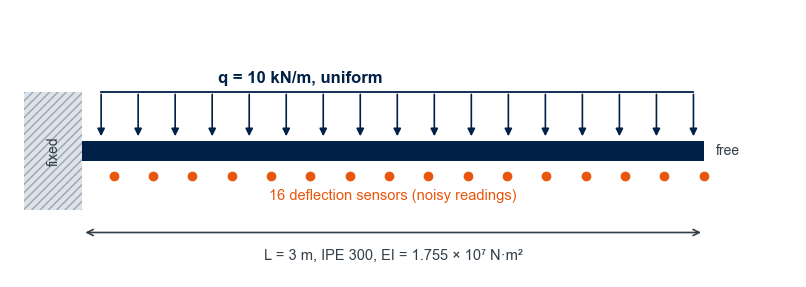

In [17]:
fig = draw_setup(point_load=False)
show(fig, "n0_setup")

### 1.1 · The sensor readings
`make_sensors` creates virtual readings: the exact deflection plus random noise. (In real life these come from instruments.)

In [18]:
xs, ys = make_sensors(16, x_first=0.05, x_last=1.0, noise=0.050, seed=2)   # seed=2: one particular noise draw
print("sensor positions x/L :", np.round(xs, 2))
print("readings (mm)        :", np.round(to_mm(ys), 2))

sensor positions x/L : [0.05 0.11 0.18 0.24 0.3  0.37 0.43 0.49 0.56 0.62 0.68 0.75 0.81 0.87
 0.94 1.  ]
readings (mm)        : [-0.09  0.12 -0.3   1.04  0.35  0.96  1.73  1.64  2.13  2.62  3.51  4.49
  4.32  4.47  5.44  5.6 ]


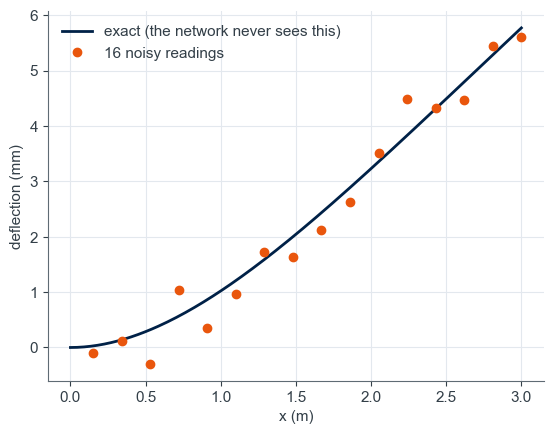

In [19]:
plt.plot(GRID * L, to_mm(w_unif(GRID)), color=NAVY, lw=2, label="exact (the network never sees this)")
plt.plot(xs * L, to_mm(ys), "o", color=ORANGE, label="16 noisy readings")
plt.xlabel("x (m)")
plt.ylabel("deflection (mm)")
plt.legend()
plt.show()

### 1.2 · Training data as tensors
The network gets the sensor positions `X` as input and must reproduce the readings `Y`. Both need shape `(16, 1)`.

In [20]:
X = torch.tensor(xs.reshape(-1, 1))     # network input : 16 sensor positions, shape (16, 1)
Y = torch.tensor(ys.reshape(-1, 1))     # network target: 16 measured deflections, shape (16, 1)
print(X.shape, Y.shape)

torch.Size([16, 1]) torch.Size([16, 1])


### 1.3 · The loss: how wrong is the network?
The **loss** is one number that says how bad the network is. Here it is the **mean squared error (MSE)**: the average of (prediction − reading)² over the sensors. Training tries to make it small.

In [21]:
torch.manual_seed(0)
net = make_net()                                    # a new, untrained network
loss = ((net(X) - Y) ** 2).mean()                   # mean over the 16 sensors of (prediction - reading)^2
print(f"loss of the untrained network: {loss.item():.5f}")

loss of the untrained network: 0.00716


### 1.4 · One training step
Every training step is the same four lines. Read the comments, then run.

1. **forward pass**: compute predictions and the loss;
2. `opt.zero_grad()`: erase the gradients left over from the previous step;
3. `loss.backward()`: **backpropagation**, computes how the loss changes when each parameter changes (the gradient, stored in `p.grad`);
4. `opt.step()`: the **optimiser** (Adam) moves every parameter a little in the direction that lowers the loss. The size of the move is the **learning rate** `lr`.

In [22]:
opt = torch.optim.Adam(net.parameters(), lr=1e-4)    # Adam: a smart gradient descent. Needs: which numbers to adjust, and lr

for step in range(5):
    loss = ((net(X) - Y) ** 2).mean()    # 1. forward pass and loss
    opt.zero_grad()                       # 2. erase old gradients
    loss.backward()                       # 3. backpropagation: fills p.grad for every parameter p
    opt.step()                            # 4. nudge every parameter downhill
    print(f"step {step}   loss = {loss.item():.5f}")

print("gradient of the loss w.r.t. the 30 weights of layer 1 has shape", tuple(net[0].weight.grad.shape))

step 0   loss = 0.00716
step 1   loss = 0.00660
step 2   loss = 0.00609
step 3   loss = 0.00563
step 4   loss = 0.00522
gradient of the loss w.r.t. the 30 weights of layer 1 has shape (30, 1)


The loss drops quickly (it may bounce a little in the first steps: Adam takes fairly large steps early on). **Training = repeating these four lines thousands of times.** We pack the whole recipe in one function, so we can reuse it:

In [23]:
def train_data_only(xs, ys, its=3000, lr=5e-3, seed=0, act=nn.Tanh, log_every=None):
    """Fit a network to the readings (xs, ys). Loss = data misfit only, there is no physics. Returns the trained network."""
    torch.manual_seed(seed)                              # same random start for the same seed
    model = make_net(act=act)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X = torch.tensor(xs.reshape(-1, 1))
    Y = torch.tensor(ys.reshape(-1, 1))
    for step in range(its):                              # its = number of iterations
        loss = ((model(X) - Y) ** 2).mean()              # data misfit and nothing else
        opt.zero_grad()
        loss.backward()
        opt.step()
        if log_every and (step % log_every == 0 or step == its - 1):
            print(f"   step {step:4d}   loss {loss.item():.2e}", flush=True)     # printed while the training runs
    return model

In [24]:
model0 = train_data_only(xs, ys, its=3000, seed=0, log_every=500)    # 3000 steps, print the loss every 500

   step    0   loss 7.16e-03
   step  500   loss 5.45e-05
   step 1000   loss 5.27e-05
   step 1500   loss 5.12e-05
   step 2000   loss 7.02e-05
   step 2500   loss 4.80e-05
   step 2999   loss 4.66e-05


The loss falls fast, then **flattens**: the network has learned what the readings can tell it. It flattens near the noise variance (noise = 5 % of the tip deflection, which is 1.0 in scaled units, so (0.05)² ≈ 2.5 × 10⁻³): the readings themselves are not exact, so a smaller loss would only mean the network is copying noise.

### 1.5 · Does it fit? Yes, very well
Now we ask the trained network for the deflection along the whole beam (201 points) and compare with the exact curve.
`R²` = 1 means a perfect fit. We also look at the clamped end: there the real deflection is exactly 0.

In [25]:
x = torch.tensor(GRID.reshape(-1, 1), requires_grad=True)   # 201 points; requires_grad because we will differentiate w.r.t. x next
w = model0(x)                                               # deflection predicted by the network
w_net = w.detach().numpy().ravel()                          # as a numpy array, for plots and numbers

R2 = r2(w_unif(GRID), w_net)
print(f"R2 of the deflection over the whole beam: {R2:.4f}   (1.0 = perfect)")
print(f"w(0) = {to_mm(w_net[0]):+.2f} mm    <- the beam is clamped here: it must be exactly 0")

R2 of the deflection over the whole beam: 0.9956   (1.0 = perfect)
w(0) = -0.09 mm    <- the beam is clamped here: it must be exactly 0


### 1.6 · The bending moment: the second derivative of the network
Engineers care about **moment**, not only deflection. For a beam, `M = EI·w''`, in scaled units simply `M = w''`. We have a network for `w`, so we get `w''` with `d` twice. Nobody told the network about moments, so we are testing what it learned *by itself*.

In [26]:
w1 = d(w, x)                               # slope  w'   (first derivative of the network with respect to x)
w2 = d(w1, x)                              # w'' = bending moment in scaled units (second derivative)
w1_net = w1.detach().numpy().ravel()
w2_net = w2.detach().numpy().ravel()

M0_err = abs(w2_net[0] - M_unif(0.0)) / M_unif(0.0)
print(f"fixed-end moment: network {to_kNm(w2_net[0]):.1f} kN m   exact {to_kNm(M_unif(0.0)):.1f} kN m   -> error {M0_err:.0%}")
print(f"fixed-end slope : network {w1_net[0]:+.4f}   exact 0 (clamped)")
print(f"error of the moment along the whole beam (relative L2): {rel_l2(M_unif(GRID), w2_net):.0%}")

fixed-end moment: network 35.4 kN m   exact 45.0 kN m   -> error 21%
fixed-end slope : network -0.0054   exact 0 (clamped)
error of the moment along the whole beam (relative L2): 44%


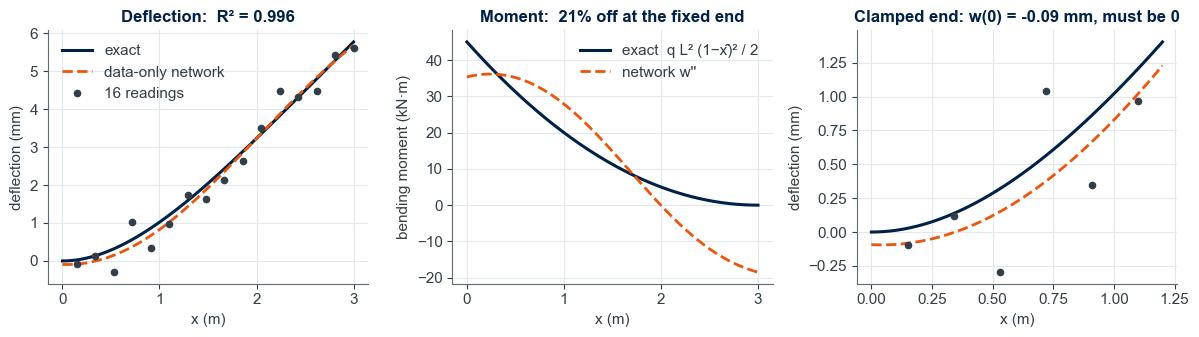

In [27]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
xm = GRID * L                                                                   # position in metres
ax[0].plot(xm, to_mm(w_unif(GRID)), color=NAVY, lw=2.2, label="exact")
ax[0].plot(xm, to_mm(w_net), color=ORANGE, lw=2, ls="--", label="data-only network")
ax[0].plot(xs * L, to_mm(ys), "o", color=INK, ms=4.5, label="16 readings")
ax[0].set(xlabel="x (m)", ylabel="deflection (mm)", title=f"Deflection:  R² = {R2:.3f}")
ax[0].legend(loc="upper left")
ax[1].plot(xm, to_kNm(M_unif(GRID)), color=NAVY, lw=2.2, label="exact  q L² (1−x̂)² / 2")
ax[1].plot(xm, to_kNm(w2_net), color=ORANGE, lw=2, ls="--", label="network w''")
ax[1].set(xlabel="x (m)", ylabel="bending moment (kN·m)", title=f"Moment:  {M0_err:.0%} off at the fixed end")
ax[1].legend()
zoom = GRID <= 0.4                                                              # zoom into the clamped end
ax[2].plot(xm[zoom], to_mm(w_unif(GRID))[zoom], color=NAVY, lw=2.2)
ax[2].plot(xm[zoom], to_mm(w_net)[zoom], color=ORANGE, lw=2, ls="--")
ax[2].plot(xs[xs <= 0.4] * L, to_mm(ys)[xs <= 0.4], "o", color=INK, ms=4.5)
ax[2].set(xlabel="x (m)", ylabel="deflection (mm)", title=f"Clamped end: w(0) = {to_mm(w_net[0]):+.2f} mm, must be 0")
show(fig, "n0_fit16")

**What just happened?** The deflection looks excellent, but the moment (the *second derivative*) is far off, and the clamp is not respected. The loss only asked *"match the 16 readings"*. Nothing in the network knows about moments, equilibrium or supports.

> ### Two different derivatives: do not mix them up
> | | derivative of the loss with respect to the **parameters** | derivative of the network output with respect to the **input x** |
> |---|---|---|
> | PyTorch call | `loss.backward()` | `torch.autograd.grad(w, x, create_graph=True)` or our helper `d(w, x)` |
> | used for | **training**: moving the 1,021 numbers | **physics**: `w'`, `w''`, `w'''`, `w''''` of the network |
> | result stored in | `p.grad` of each parameter | a new tensor that you keep |
>
> A PINN uses both: `d(...)` builds the physics residual from the network, then `loss.backward()` trains the network to make that residual small.

### 1.7 · Is this draw typical? (optional: skip if short of time)
Same experiment with ten different noise draws (same network, same start). To keep the cell short we pack "predict and differentiate" in a helper, `predict`:

In [28]:
def predict(model, xg=GRID, deriv=d):
    """network output w and its first two derivatives w' and w'' on a grid, as numpy arrays"""
    x = torch.tensor(xg.reshape(-1, 1), requires_grad=True)
    w = model(x)
    w1 = deriv(w, x)
    w2 = deriv(w1, x)
    return [t.detach().numpy().ravel() for t in (w, w1, w2)]

In [29]:
r2_scan = []                                                     # R2 of the deflection, one entry per noise draw
M0_err_scan = []                                                 # relative error of the fixed-end moment, one entry per noise draw
for s in range(10):
    xs_s, ys_s = make_sensors(16, 0.05, 1.0, 0.05, seed=s)       # noise draw number s (the same 5 % noise as above)
    w_s, _, w2_s = predict(train_data_only(xs_s, ys_s, its=3000, seed=0))
    r2_scan.append(r2(w_unif(GRID), w_s))
    M0_err_scan.append(abs(w2_s[0] - 0.5) / 0.5)                 # exact fixed-end moment is 0.5 (scaled)
r2_scan = np.array(r2_scan)
M0_err_scan = np.array(M0_err_scan)

print("noise draw    R2 of w    error of M(0)")
for s in range(10):
    print(f"{s:8d}   {r2_scan[s]:8.3f}   {M0_err_scan[s]:10.0%}" + ("   <- used above" if s == 2 else ""))
print(f"\nmedian R2 = {np.median(r2_scan):.3f};  M(0) error: median {np.median(M0_err_scan):.0%}, "
      f"range {M0_err_scan.min():.0%} to {M0_err_scan.max():.0%}")

noise draw    R2 of w    error of M(0)
       0      0.985          52%
       1      0.998           6%
       2      0.996          21%   <- used above
       3      0.987          23%
       4      0.999          32%
       5      0.994          70%
       6      0.994           1%
       7      0.994          11%
       8      0.992          44%
       9      0.989          18%

median R2 = 0.994;  M(0) error: median 22%, range 1% to 70%


**Take-away.** Whatever the noise draw, the deflection fit looks good (R² close to 1), while the error of the fixed-end moment is much larger and changes a lot from draw to draw (read the table). *A good fit to the data does not mean the physics is right.*

---
# Part 2 · Where there are no sensors
Now put only **eight sensors on the first half** of the beam (x from 0.05 L to 0.5 L). We train the same network from five different random starts (`seed` = 0 … 4) on the same readings.

In [30]:
xs8, ys8 = make_sensors(8, x_first=0.05, x_last=0.5, noise=0.10, seed=0)

curves = []
for init in range(5):                                           # five random starts of the same network
    model = train_data_only(xs8, ys8, its=3000, seed=init)
    curves.append(predict(model)[0])                            # keep the predicted deflection on the whole beam
curves = np.array(curves)

In [31]:
r2_half = []                                          # fit quality over the WHOLE beam, one entry per start
for k in range(5):
    r2_half.append(r2(w_unif(GRID), curves[k]))
tip_ratio = curves[:, -1] / w_unif(1.0)               # predicted tip deflection divided by the exact one
print("start seed   R2 (whole beam)   tip deflection / exact")
for i in range(5):
    print(f"{i:9d}   {r2_half[i]:14.2f}   {tip_ratio[i]:20.2f}")

start seed   R2 (whole beam)   tip deflection / exact
        0             0.57                   0.52
        1             0.56                   0.52
        2             0.50                   0.48
        3             0.51                   0.48
        4             0.56                   0.52


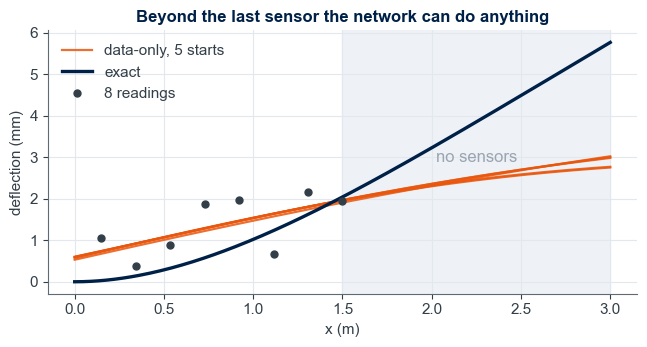

In [32]:
fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.axvspan(0.5 * L, L, color="#EEF2F6", zorder=0)
ax.text(0.75 * L, 0.5, "no sensors", ha="center", color=GREY, fontsize=12, transform=ax.get_xaxis_transform())
for i, c in enumerate(curves): ax.plot(GRID * L, to_mm(c), color=ORANGE, lw=1.6, alpha=0.85, label="data-only, 5 starts" if i == 0 else None)
ax.plot(GRID * L, to_mm(w_unif(GRID)), color=NAVY, lw=2.4, label="exact")
ax.plot(xs8 * L, to_mm(ys8), "o", color=INK, ms=5, label="8 readings")
ax.set(xlabel="x (m)", ylabel="deflection (mm)", title="Beyond the last sensor the network can do anything")
ax.legend(loc="upper left")
show(fig, "n0_nosensors")

**Take-away.** All five networks fit the eight readings equally well. Beyond the last sensor they disagree with each other *and* with the truth. Fitting data says nothing about the structure. **Physics has to supply what the data cannot.**

---
# Part 3 · Derivatives of a network: finite differences or autodiff?
A PINN needs `w'`, `w''`, `w'''` and `w''''` of the network at many points. There are two ways to get a derivative on a computer:

1. **Finite differences:** evaluate the function at nearby points and divide, `(f(x+h) − f(x)) / h`, with a small step `h`.
2. **Automatic differentiation:** the `d` helper from Part A: exact, no step size.

We test both on a function whose derivatives we know exactly: `f(x) = sin 3x` at `x = 0.4`.
`f' = 3 cos 3x`, `f'' = −9 sin 3x`, `f''' = −27 cos 3x`, `f'''' = 81 sin 3x`.

### 3.1 · Autodiff
`nth_derivative(y, x, n)` simply applies `d` n times.

In [33]:
def nth_derivative(y, x, n):
    """n-th derivative of y with respect to x: apply d() n times (n = 0 returns y itself)"""
    for _ in range(n):
        y = d(y, x)
    return y

xt = torch.tensor([[0.4]], requires_grad=True)
ft = torch.sin(3 * xt)                                           # f(x) = sin(3x) as a PyTorch formula
exact = [np.sin(1.2), 3*np.cos(1.2), -9*np.sin(1.2), -27*np.cos(1.2), 81*np.sin(1.2)]    # exact values at x = 0.4

ad = []                                                          # derivatives of order 0 ... 4 by autodiff
ad_err = []                                                      # ... and their errors against the exact values
for n in range(5):
    ad.append(nth_derivative(ft, xt, n).item())
    ad_err.append(abs(ad[n] - exact[n]))
for n in range(5):
    print(f"derivative {n}:  autograd {ad[n]:+.10f}   error {ad_err[n]:.1e}")

derivative 0:  autograd +0.9320390860   error 1.1e-16
derivative 1:  autograd +1.0870732634   error 6.7e-16
derivative 2:  autograd -8.3883517737   error 1.8e-15
derivative 3:  autograd -9.7836593709   error 5.3e-15
derivative 4:  autograd +75.4951659633   error 0.0e+00


The errors are about 10⁻¹⁵: that is the rounding limit of 64-bit numbers. **Autodiff is exact at every order.**

### 3.2 · Finite differences
Three formulas (`f` is any function, `h` the step):
- *forward difference* for `f'`: error shrinks like `h`;
- *central difference* for `f'`: error shrinks like `h²` (better);
- a *five-point stencil* for `f''''` (needs five function values).

In [34]:
def f_np(x):
    """the same function, now as a plain numpy function"""
    return np.sin(3 * x)

x0 = 0.4

def fd_forward(f, x, h): return (f(x + h) - f(x)) / h
def fd_central(f, x, h): return (f(x + h) - f(x - h)) / (2 * h)
def fd_central4(f, x, h):           # fourth derivative from five points
    return (f(x + 2*h) - 4*f(x + h) + 6*f(x) - 4*f(x - h) + f(x - 2*h)) / h**4

**Intuition first.** The smaller the step `h`, the better the formula should be. Is that true? Look at the error of `f'` as `h` shrinks:

In [35]:
for h in [1e-1, 1e-4, 1e-8, 1e-12]:
    print(f"h = {h:.0e}   error of the forward difference = {abs(fd_forward(f_np, x0, h) - exact[1]):.1e}")

h = 1e-01   error of the forward difference = 4.3e-01
h = 1e-04   error of the forward difference = 4.2e-04
h = 1e-08   error of the forward difference = 4.3e-08
h = 1e-12   error of the forward difference = 5.4e-05


The error first falls, then **grows again** for very small `h`: subtracting two almost equal numbers loses digits (round-off error). So there is a "sweet spot", and for higher derivatives it is much worse. Full table:

In [36]:
hs = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-8, 1e-10, 1e-12])      # steps to try for f'
h4 = np.array([1e-1, 1e-2, 1e-3, 1e-4, 1e-5])                                # steps to try for f''''
err_fwd = np.abs(fd_forward(f_np, x0, hs) - exact[1])                        # the formulas work on a whole array of steps at once
err_cen = np.abs(fd_central(f_np, x0, hs) - exact[1])
err_4 = np.abs(fd_central4(f_np, x0, h4) - exact[4])

print("   h        forward error   central error   |   h     error of f''''")
for i, h in enumerate(hs):
    right = f"   {h4[i]:.0e}   {err_4[i]:.1e}" if i < len(h4) else ""
    print(f"{h:8.0e}   {err_fwd[i]:12.1e}   {err_cen[i]:12.1e}   |{right}")
print(f"autograd:         f' error {ad_err[1]:.1e}                   |   f'''' error {ad_err[4]:.1e}")

   h        forward error   central error   |   h     error of f''''
   1e-01        4.3e-01        1.6e-02   |   1e-01   1.1e+00
   1e-02        4.2e-02        1.6e-04   |   1e-02   1.1e-02
   1e-03        4.2e-03        1.6e-06   |   1e-03   1.1e-04
   1e-04        4.2e-04        1.6e-08   |   1e-04   1.0e+01
   1e-05        4.2e-05        1.6e-10   |   1e-05   3.3e+04
   1e-06        4.2e-06        2.4e-11   |
   1e-08        4.3e-08        1.3e-09   |
   1e-10        5.0e-07        5.4e-08   |
   1e-12        5.4e-05        1.6e-06   |
autograd:         f' error 6.7e-16                   |   f'''' error 0.0e+00


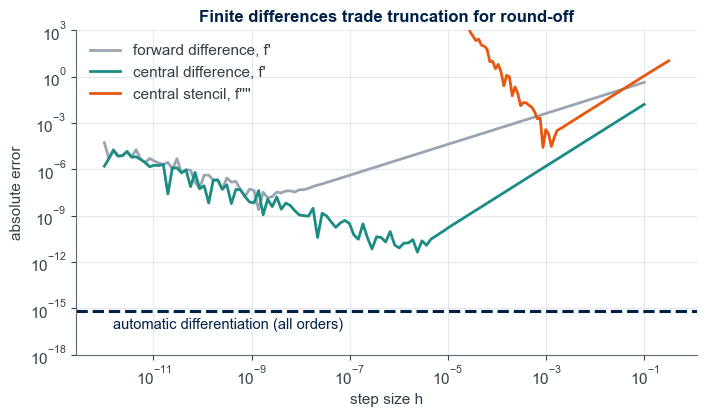

In [37]:
fig, ax = plt.subplots(figsize=(7.2, 4.3))
hf = np.logspace(-12, -1, 120)                                    # many step sizes, for a smooth curve
ax.loglog(hf, np.abs(fd_forward(f_np, x0, hf) - exact[1]), color=GREY, lw=2, label="forward difference, f'")
ax.loglog(hf, np.abs(fd_central(f_np, x0, hf) - exact[1]), color=TEAL, lw=2, label="central difference, f'")
hf4 = np.logspace(-5, -0.5, 80)
ax.loglog(hf4, np.abs(fd_central4(f_np, x0, hf4) - exact[4]), color=ORANGE, lw=2, label="central stencil, f''''")
ax.axhline(max(ad_err[1], 1e-17), color=NAVY, lw=2.2, ls="--")
ax.text(1.5e-12, 3e-17, "automatic differentiation (all orders)", color=NAVY, fontsize=10.5, va="bottom")
ax.set(xlabel="step size h", ylabel="absolute error", ylim=(1e-18, 1e3), title="Finite differences trade truncation for round-off")
ax.legend(loc="upper left")
show(fig, "n0_fd_error")

**Take-away.** Finite differences have a sweet spot in `h` that moves with the derivative order, and the fourth derivative is the worst. Autodiff has no step size and is exact at every order: *one more call of `d` gives the next derivative*.

### 3.3 · The derivative ladder of the beam, by autodiff only
Start from the exact deflection formula of the beam and differentiate it four times with `d`. The five curves are deflection → slope → moment → shear → load.

In [ ]:
xl = torch.tensor(GRID.reshape(-1, 1), requires_grad=True)
wl = xl**2 * (6 - 4*xl + xl**2) / 3                   # exact deflection (scaled), written as a PyTorch formula
w1l = d(wl, xl)                                       # slope
w2l = d(w1l, xl)                                      # moment
w3l = d(w2l, xl)                                      # shear (with a minus sign)
w4l = d(w3l, xl)                                      # load
ladder = []                                           # the five curves as numpy arrays: w, w', w'', w''', w''''
for t in (wl, w1l, w2l, w3l, w4l):
    ladder.append(t.detach().numpy().ravel())

# the same derivatives worked out by hand:  w' = 4x(3 - 3x + x^2)/3,  w'' = M,  w''' = -V,  w'''' = 8
w_slope = 4 * GRID * (3 - 3*GRID + GRID**2) / 3
err_slope = np.abs(ladder[1] - w_slope).max()
err_moment = np.abs(ladder[2] - M_unif(GRID)).max()
err_shear = np.abs(ladder[3] + V_unif(GRID)).max()
err_load = np.abs(ladder[4] - 8).max()
err_ladder = [err_slope, err_moment, err_shear, err_load]
print(f"w'   slope :  largest difference from the hand formula: {err_slope:.1e}")
print(f"w''  moment:  largest difference from the hand formula: {err_moment:.1e}")
print(f"w''' shear :  largest difference from the hand formula: {err_shear:.1e}")
print(f"w''''load  :  largest difference from the hand formula: {err_load:.1e}")

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(13, 2.6))
titles = ["w  deflection", "w'  slope", "w''  moment", "w'''  shear", "w''''  (= 8 x load)"]
for k in range(5):
    ax[k].plot(GRID, ladder[k], color=NAVY if k < 4 else ORANGE, lw=2.2)
    ax[k].set_title(titles[k], fontsize=11)
    ax[k].set_xlabel("x / L")
    ax[k].set_xticks([0, 0.5, 1])
show(fig, "n0_ladder")

---
# Part 4 · Which activation functions can be differentiated four times?
The activation function decides what the network can do. A **ReLU** network (`max(0, x)`) is piecewise *straight*: its slope is constant, so its **second derivative is zero almost everywhere**. A beam needs `w''` and `w''''`, so ReLU would give the physics no signal. We need a smooth activation: **tanh**, or **SiLU** (also called swish).

First, a small safety net: with ReLU the second derivative does not depend on `x` at all, so PyTorch may return `None` (or complain). The helper below turns that into zeros:

In [40]:
def d_safe(y, x):
    """like d(), but returns zeros when y does not depend on x (needed to show what a ReLU network does)"""
    if not y.requires_grad:                                  # y is a constant
        return torch.zeros_like(x)
    g = torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True, allow_unused=True)[0]   # allow_unused: don't fail
    return torch.zeros_like(x) if g is None else g           # None means "y does not depend on x"

We fit three networks of the same size, with different activations, to 40 exact deflection values, and compare the second derivative `w''` with the exact bending moment.

In [41]:
xs_fit = np.linspace(0.0, 1.0, 40)
ys_fit = w_unif(xs_fit)                                      # 40 exact deflection values, no noise
acts = {"ReLU": nn.ReLU, "tanh": nn.Tanh, "SiLU (swish)": nn.SiLU}
w_act, M_act, err_act = {}, {}, {}
for name, act in acts.items():
    net = train_data_only(xs_fit, ys_fit, its=3000, seed=0, act=act)
    w_act[name], _, M_act[name] = predict(net, deriv=d_safe)
    err_act[name] = (100 * rel_l2(w_unif(GRID), w_act[name]), 100 * rel_l2(M_unif(GRID), M_act[name]))
    print(f"{name:13s} deflection error {err_act[name][0]:6.2f} %      error of w'' against the exact moment {err_act[name][1]:6.1f} %")

ReLU          deflection error   0.34 %      error of w'' against the exact moment  100.0 %
tanh          deflection error   0.91 %      error of w'' against the exact moment   38.3 %
SiLU (swish)  deflection error   0.08 %      error of w'' against the exact moment    5.4 %


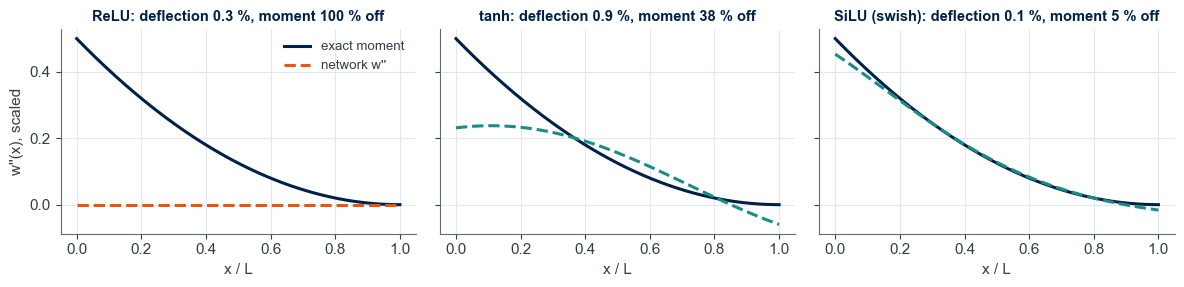

In [42]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.0), sharey=True)
for k, name in enumerate(acts):
    ax[k].plot(GRID, M_unif(GRID), color=NAVY, lw=2.2, label="exact moment")
    ax[k].plot(GRID, M_act[name], color=ORANGE if name == "ReLU" else TEAL, lw=2.2, ls="--", label="network w''")
    ax[k].set_title(f"{name}: deflection {err_act[name][0]:.1f} %, moment {err_act[name][1]:.0f} % off", fontsize=10.5)
    ax[k].set_xlabel("x / L")
ax[0].set_ylabel("w''(x), scaled")
ax[0].legend(loc="upper right", fontsize=9.5)
show(fig, "n0_activations")

**Take-away.** All three fit the *deflection* well, but ReLU's second derivative is flat zero: it cannot represent a bending moment. A PINN for the beam differentiates the network four times, so the activation has to be smooth. We use **tanh**; SiLU would also work (change one word in `make_net`).

**Next:** N1 builds the forward PINN. The derivatives you made with `d` become the *physics loss*.

---
# PyTorch cheat-sheet (everything used in N0–N3)

| What you write | What it does | Where you saw it |
|---|---|---|
| `torch.tensor(data)` | make a tensor from a list or numpy array | A1 |
| `x.shape`, `x.dtype`, `x.device` | size, kind of number, CPU or GPU | A1 |
| `x.reshape(-1, 1)` | turn a flat list into a column `(N, 1)`: the shape networks want | A1 |
| `x.item()` | one number out of a tensor | A1 |
| `x.detach().numpy()` | tensor → numpy array (for plots and printing) | A2, 1.5 |
| `torch.tensor(..., requires_grad=True)` | "record what happens to this tensor, I will differentiate with respect to it" | A2 |
| `torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True)[0]` | derivative of `y` with respect to `x` at every point; `create_graph=True` lets you differentiate again | A2, helper `d(y, x)` |
| `nn.Linear(n_in, n_out)` | a layer of `n_out` neurons | A3 |
| `nn.Tanh()`, `nn.ReLU()`, `nn.SiLU()` | activation functions (a PINN needs a smooth one: tanh, SiLU) | A3, part 4 |
| `nn.Sequential(...)` | chain layers into a network | A3 |
| `model(x)` | forward pass: network output for input `x` | A3 |
| `model.parameters()` | all adjustable numbers of the network | A3, 1.4 |
| `torch.manual_seed(0)` | fix the random numbers, so a run can be repeated | A3 |
| `torch.rand(n, 1)` | `n` random numbers between 0 and 1 (random collocation points, from N1 on) | N1 |
| `torch.exp(t)` | `e^t` (we use it to keep the unknown load positive, N2) | N2 |
| `torch.optim.Adam(params, lr=...)` | the optimiser | 1.4 |
| `opt.zero_grad()` · `loss.backward()` · `opt.step()` | the three lines of every training step (after computing the loss) | 1.4 |
| `loss.item()` | the loss as a plain number, for printing | 1.4 |

**Common error messages** (you will meet them in N1–N3):

| Message (shortened) | Usual cause | Fix |
|---|---|---|
| `element 0 of tensors does not require grad` | you differentiated something PyTorch did not record: `create_graph=True` missing, or the input was created without `requires_grad=True` | use `d(...)`; create the input with `requires_grad=True` |
| `One of the differentiated Tensors appears to not have been used in the graph` | the output does not depend on the `x` you passed (a different tensor, or a ReLU) | differentiate with respect to the same `x` the network was given |
| `Can't call numpy() on Tensor that requires grad` | tried to convert a tensor that is part of a gradient calculation | `t.detach().numpy()` |
| `mat1 and mat2 shapes cannot be multiplied` | input has shape `(N,)` instead of `(N, 1)` | `x.reshape(-1, 1)` |
| `expected scalar type Double but found Float` | mixed 32-bit and 64-bit numbers | `torch.set_default_dtype(torch.float64)` at the top, before building anything |
| loss becomes `nan` | learning rate too large, or an unscaled problem | smaller `lr`; scale the problem (N1 part D) |